In [40]:
import sys
import os
import numpy as np
import pandas as pd


from utils_worm import artificializer
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils
from models import hgm
from models import bom

In [41]:
import importlib
importlib.reload(artificializer)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/src/../../../models/hgm.py'>

In [42]:
dims_generation = 2
weights = (0.1, -0.25)

# read_ids_gcamp = list(range(0, 33+1))
# read_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
read_ids_gcamp = [19]
plot_id_gcamp = 19

In [43]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])

In [44]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx_gcamp = file_ids_gcamp.index(plot_id_gcamp)

selection_n = [label for label in selection_n if label in traces_gcamp[plot_idx_gcamp].columns]
# discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

In [51]:
# generate

plot_id_art = plot_id_gcamp

file_ids_art = list()
filenames_art = list()

discrete_states_art = list()
eigenworms_art = list()

modes_art = list()
traces_reconstructed_art = list()
traces_residual_art = list()
traces_art = list()

for i in range(len(file_ids_gcamp)):
	(filename_art,
	 neural_modes_art_,
	 traces_reconstructed_art_,
	 traces_residual_art_,
	 traces_art_,
	 params_art_,
	 params_cca_art_) = artificializer.artificialize(weights, hgm,
													 filenames_gcamp[i],
													 traces_gcamp[i].columns,
													 eigenworms_gcamp[i],
													 [ds[selection_bhl] for ds in discrete_states_gcamp][i],
													 n_dimensions=dims_generation)
	filenames_art.append(filename_art)

	modes_art.append(neural_modes_art_)
	traces_reconstructed_art.append(traces_reconstructed_art_)
	traces_residual_art.append(traces_residual_art_)
	traces_art.append(traces_art_)

	file_ids_art.append(file_ids_gcamp[i])

	discrete_states_art.append(discrete_states_gcamp[i].copy())
	eigenworms_art.append(eigenworms_gcamp[i].copy())

plot_idx_art = file_ids_art.index(plot_id_art)

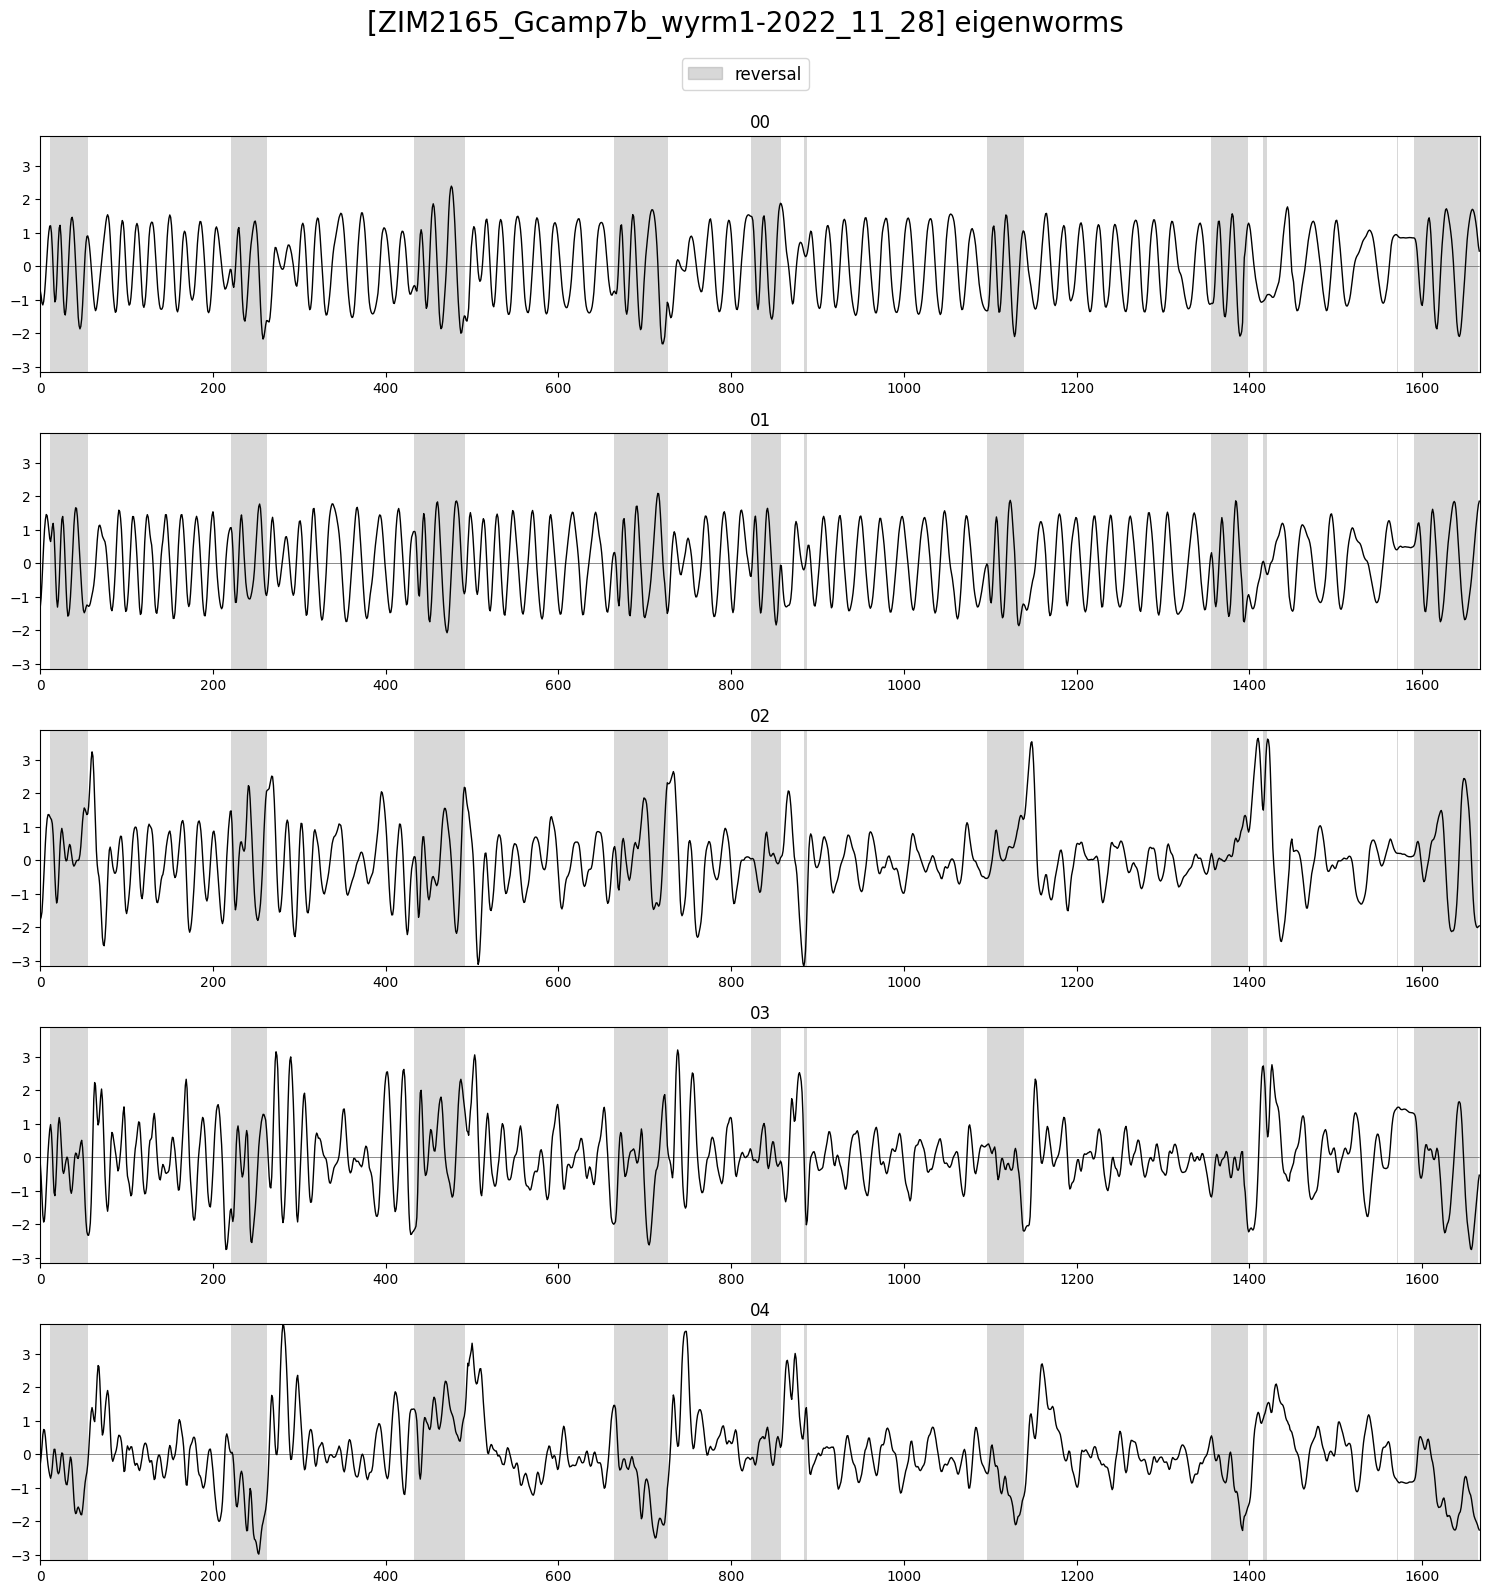

In [53]:
plot_utils.plot_traces(eigenworms_art[plot_idx_art],
					   discrete_states_art[plot_idx_art][['REV']],
					   label='reversal',
					   title=f'[{filenames_art[plot_idx_art]}] eigenworms', ylimits=None, plots_per_row=1)

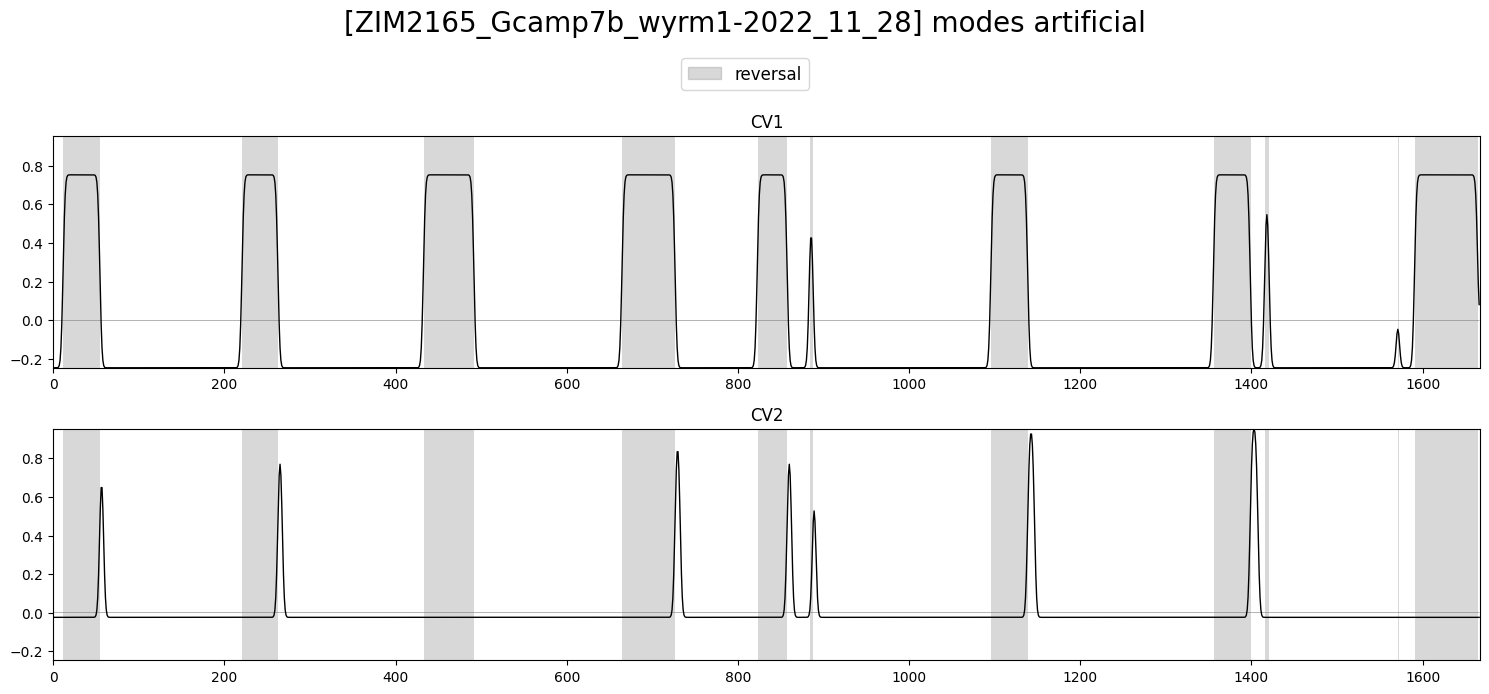

In [54]:
plot_utils.plot_traces(modes_art[plot_idx_art],
					   discrete_states_art[plot_idx_art][['REV']],
					   label='reversal',
					   title=f'[{filenames_art[plot_idx_art]}] modes artificial', ylimits=None, plots_per_row=1)

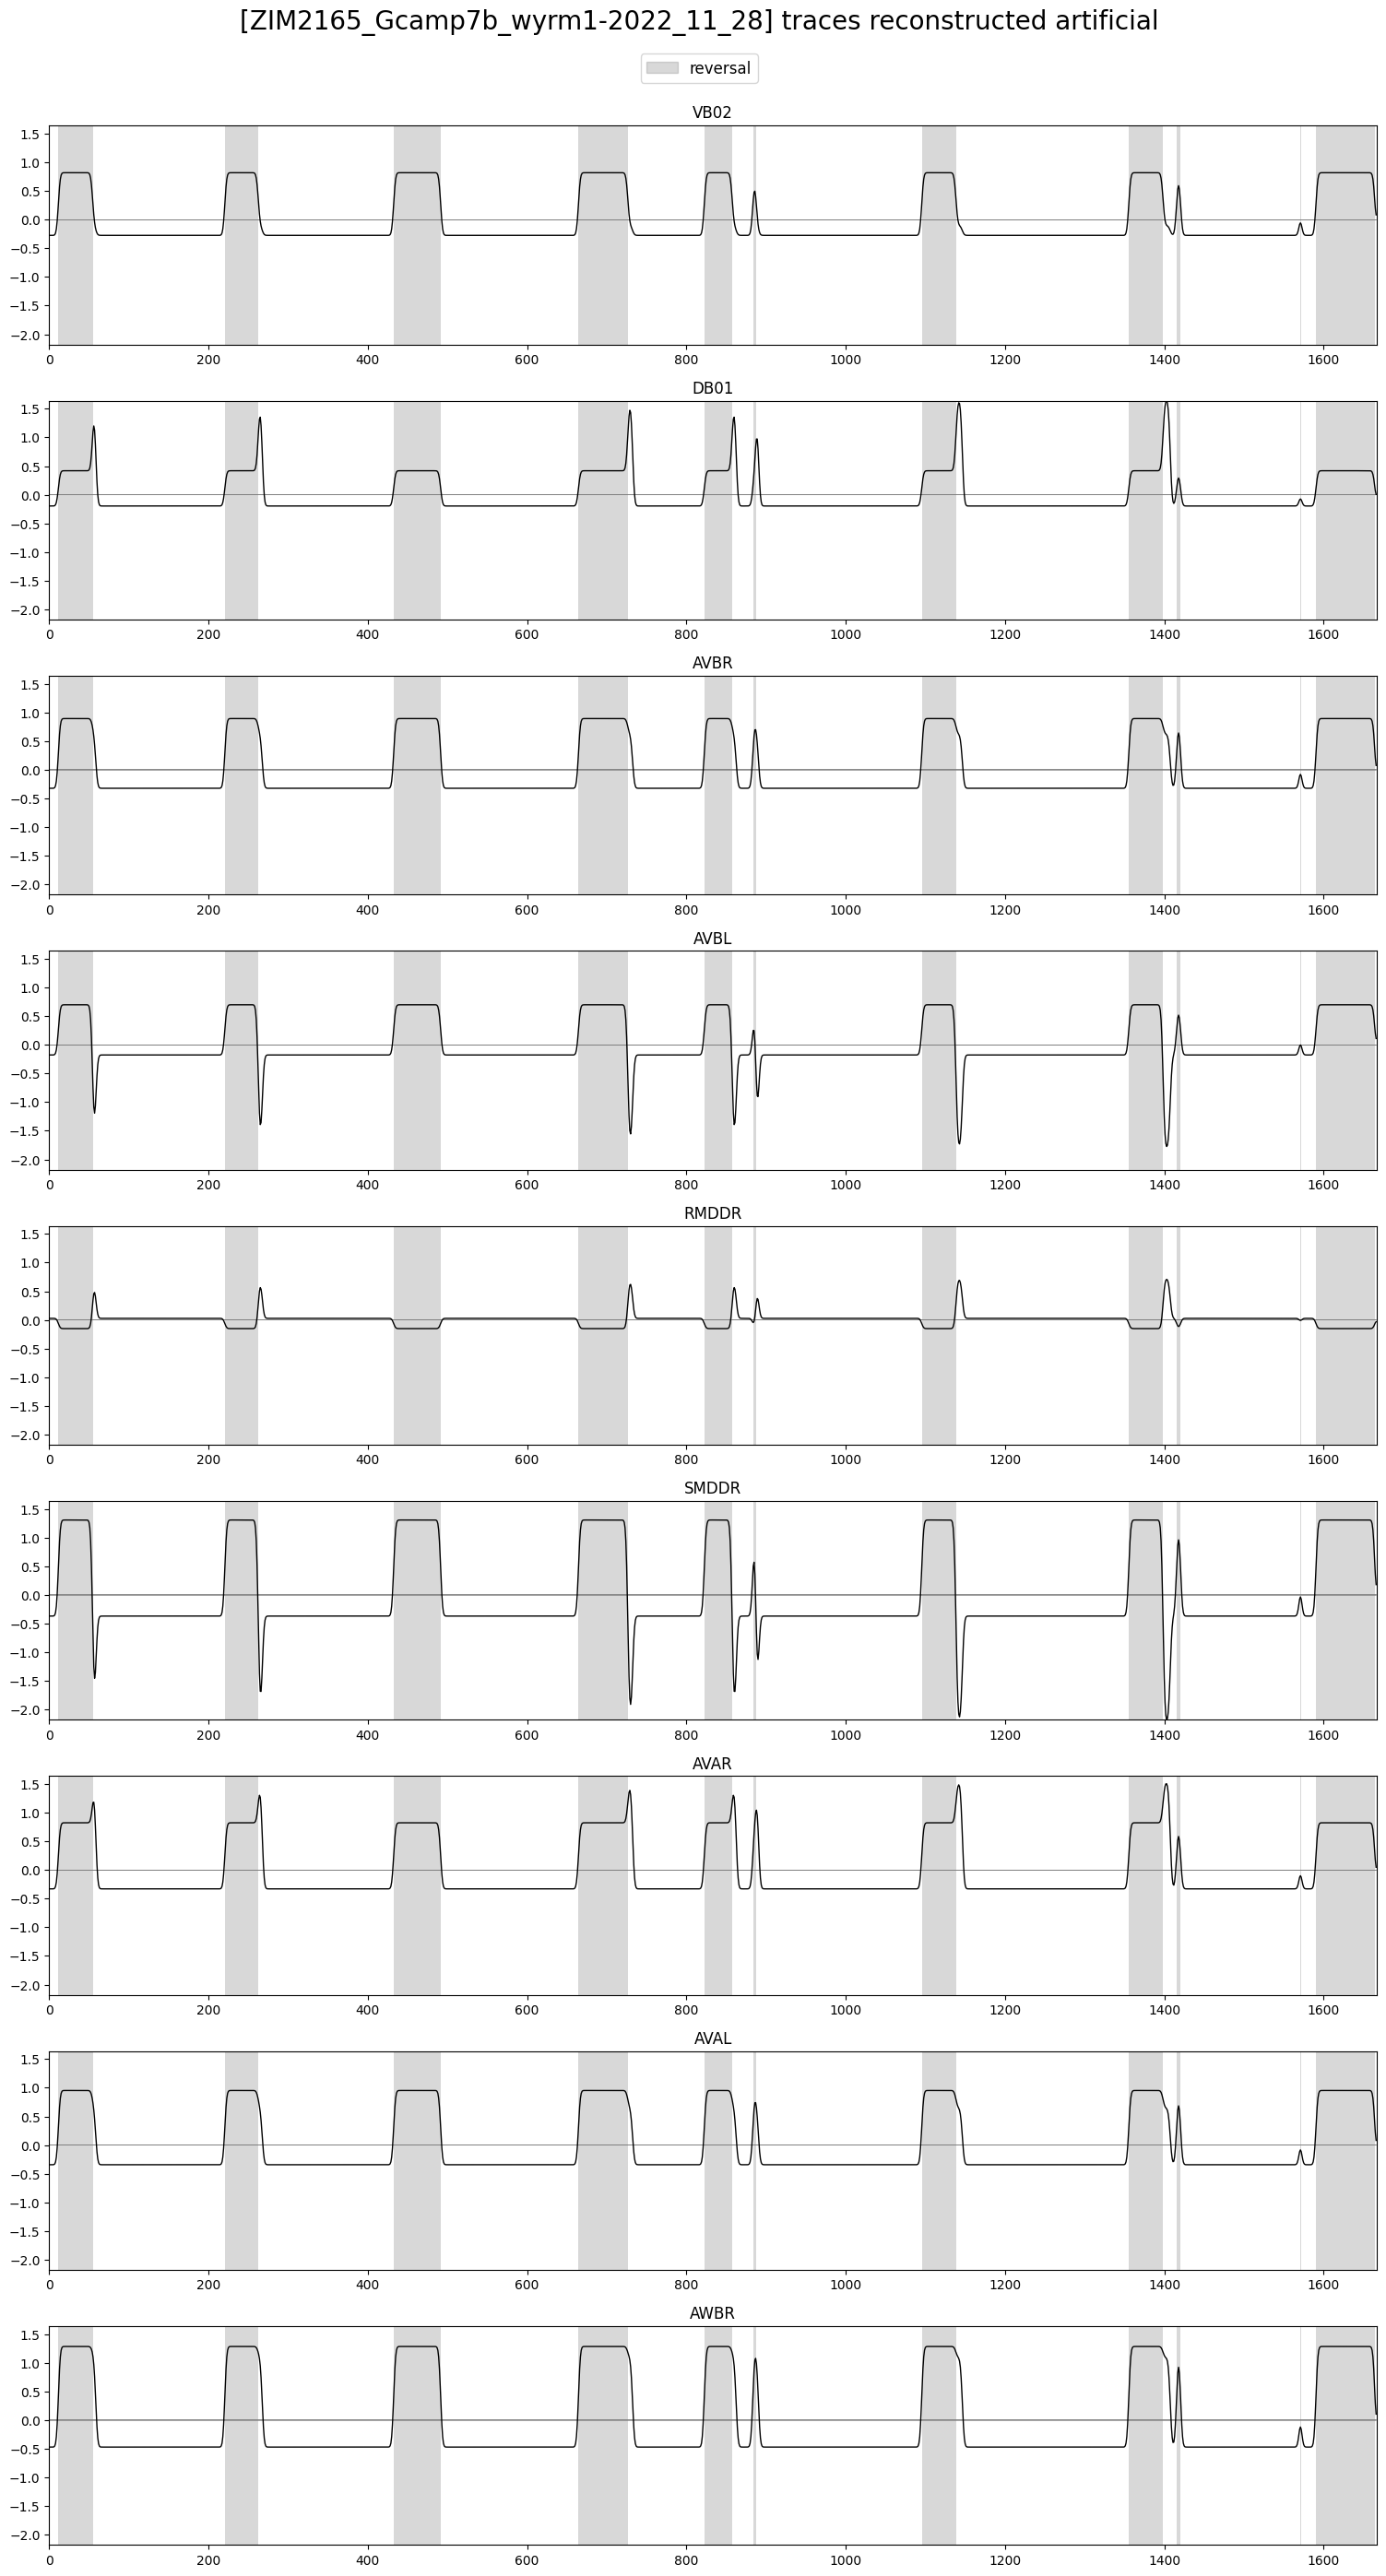

In [55]:
plot_utils.plot_traces(traces_reconstructed_art[plot_idx_art][selection_n],
					   discrete_states_art[plot_idx_art][['REV']],
					   label='reversal',
					   title=f'[{filenames_art[plot_idx_art]}] traces reconstructed artificial', ylimits=None, plots_per_row=1)

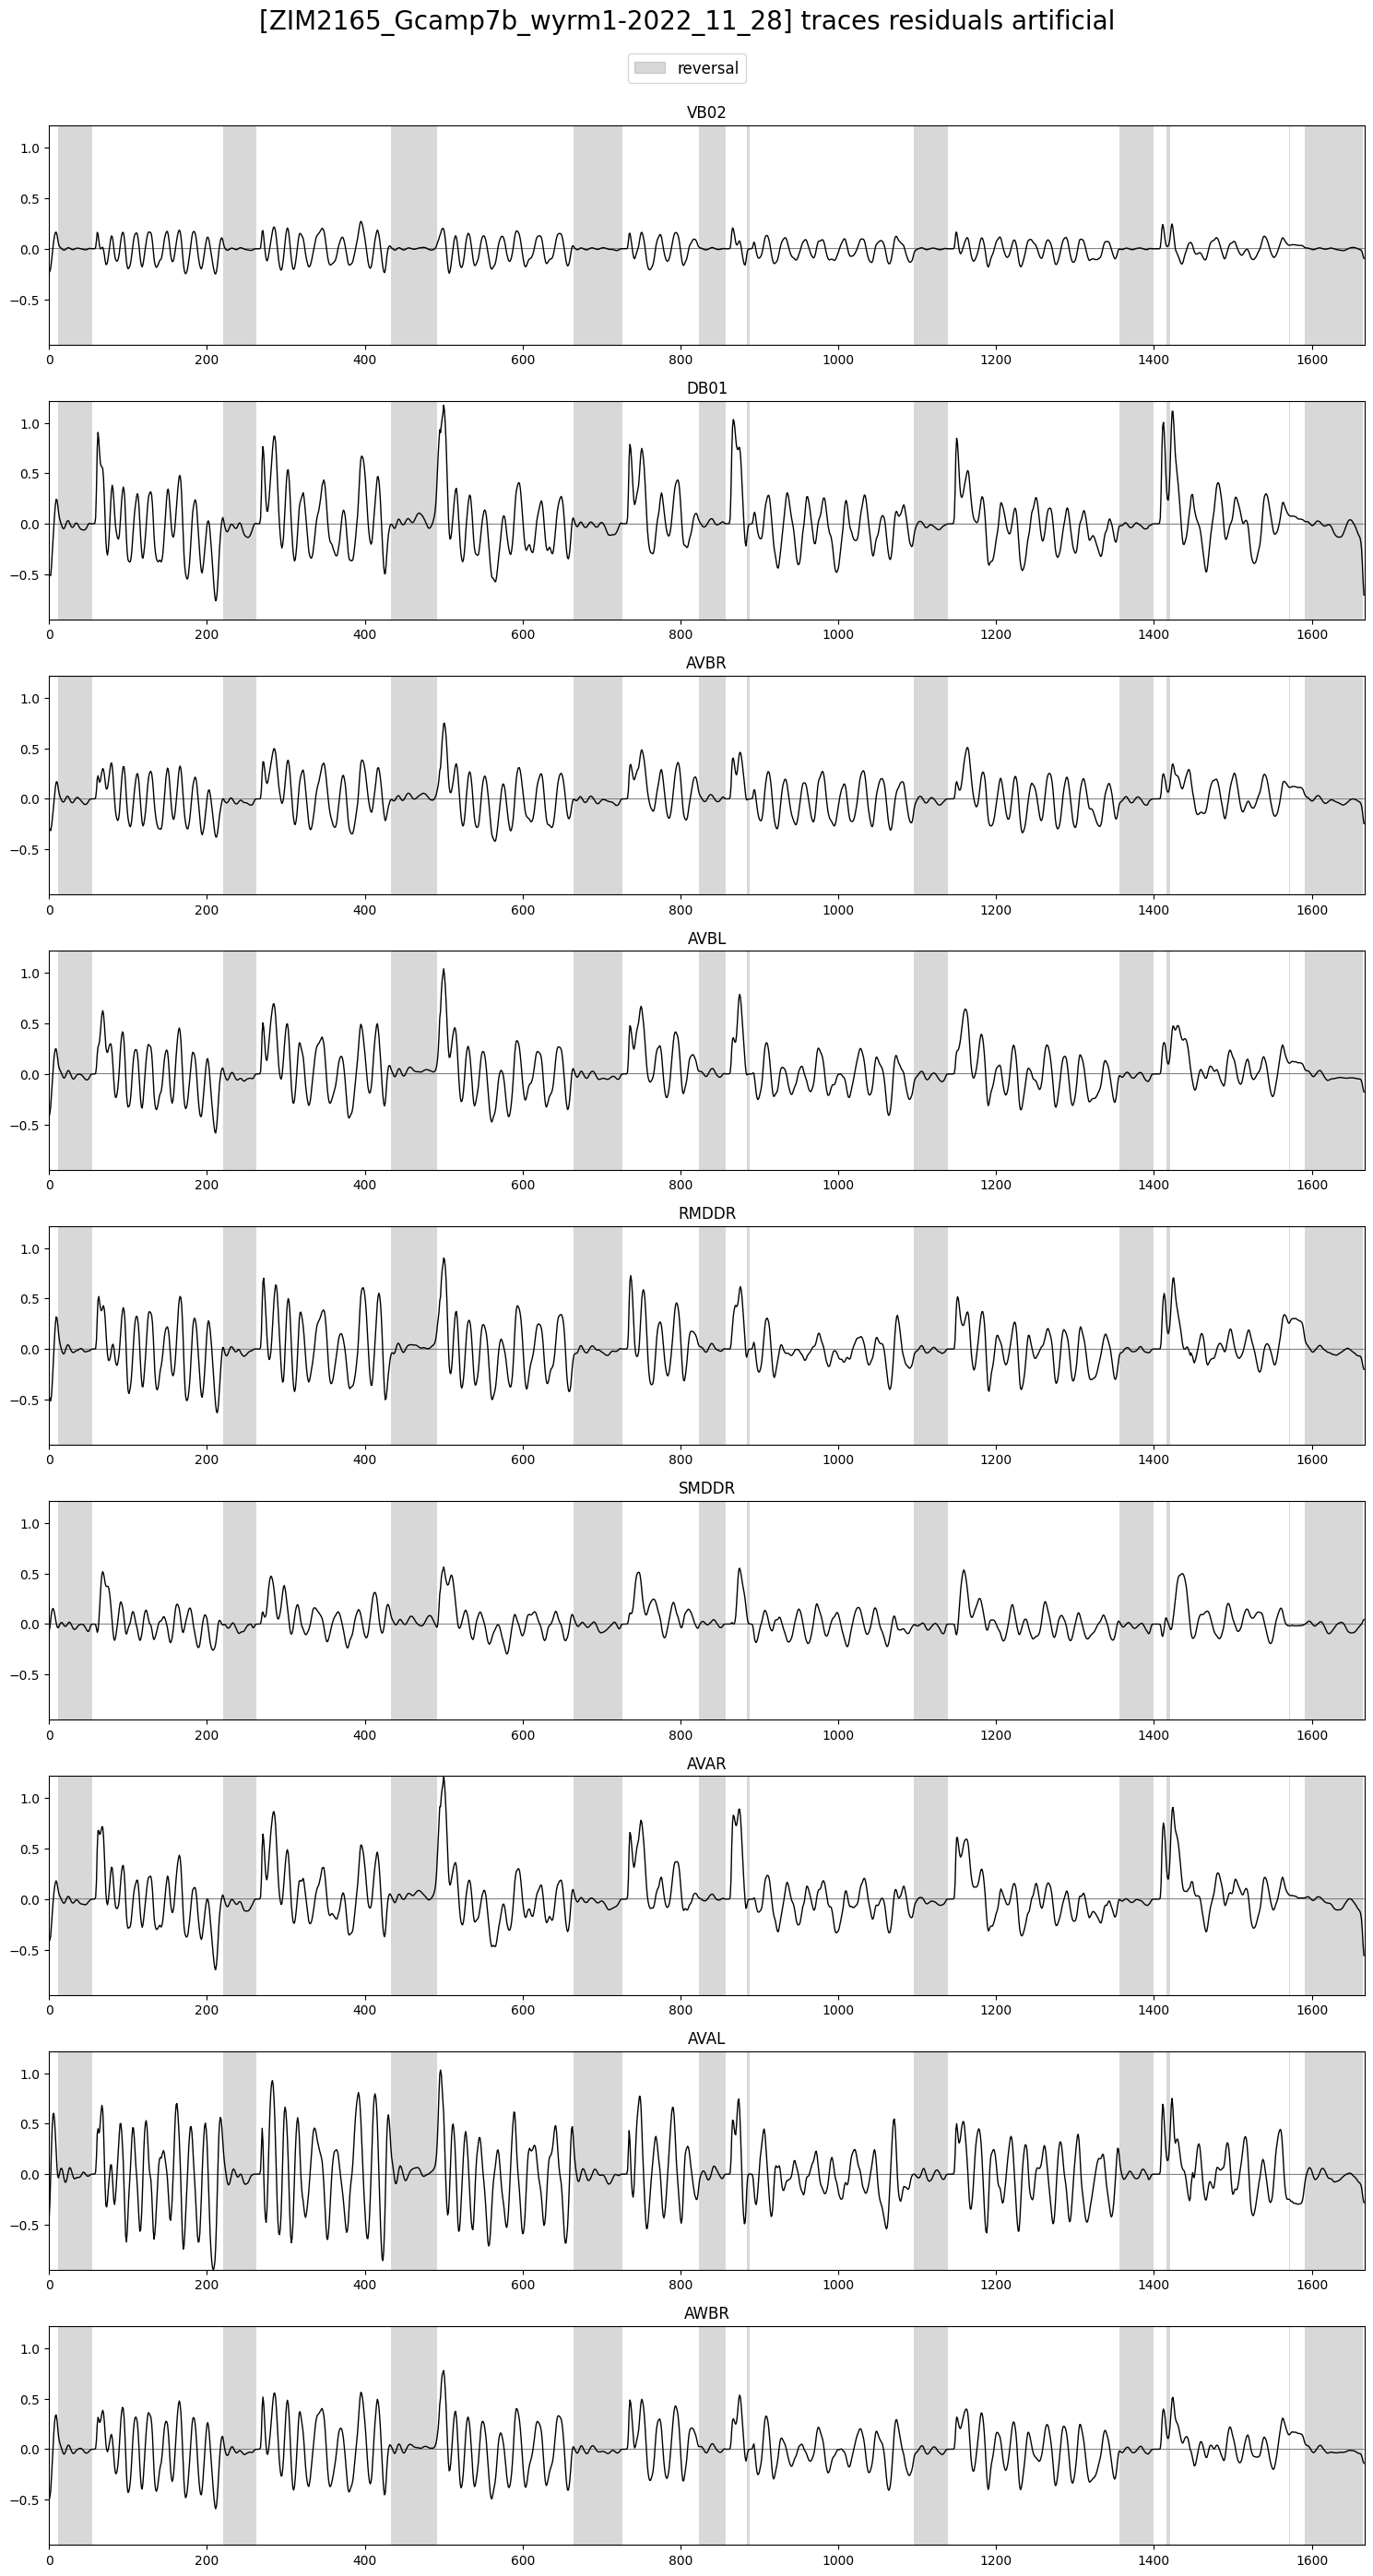

In [56]:
plot_utils.plot_traces(traces_residual_art[plot_idx_art][selection_n],
					   discrete_states_art[plot_idx_art][['REV']],
					   label='reversal',
					   title=f'[{filenames_art[plot_idx_art]}] traces residuals artificial', ylimits=None, plots_per_row=1)

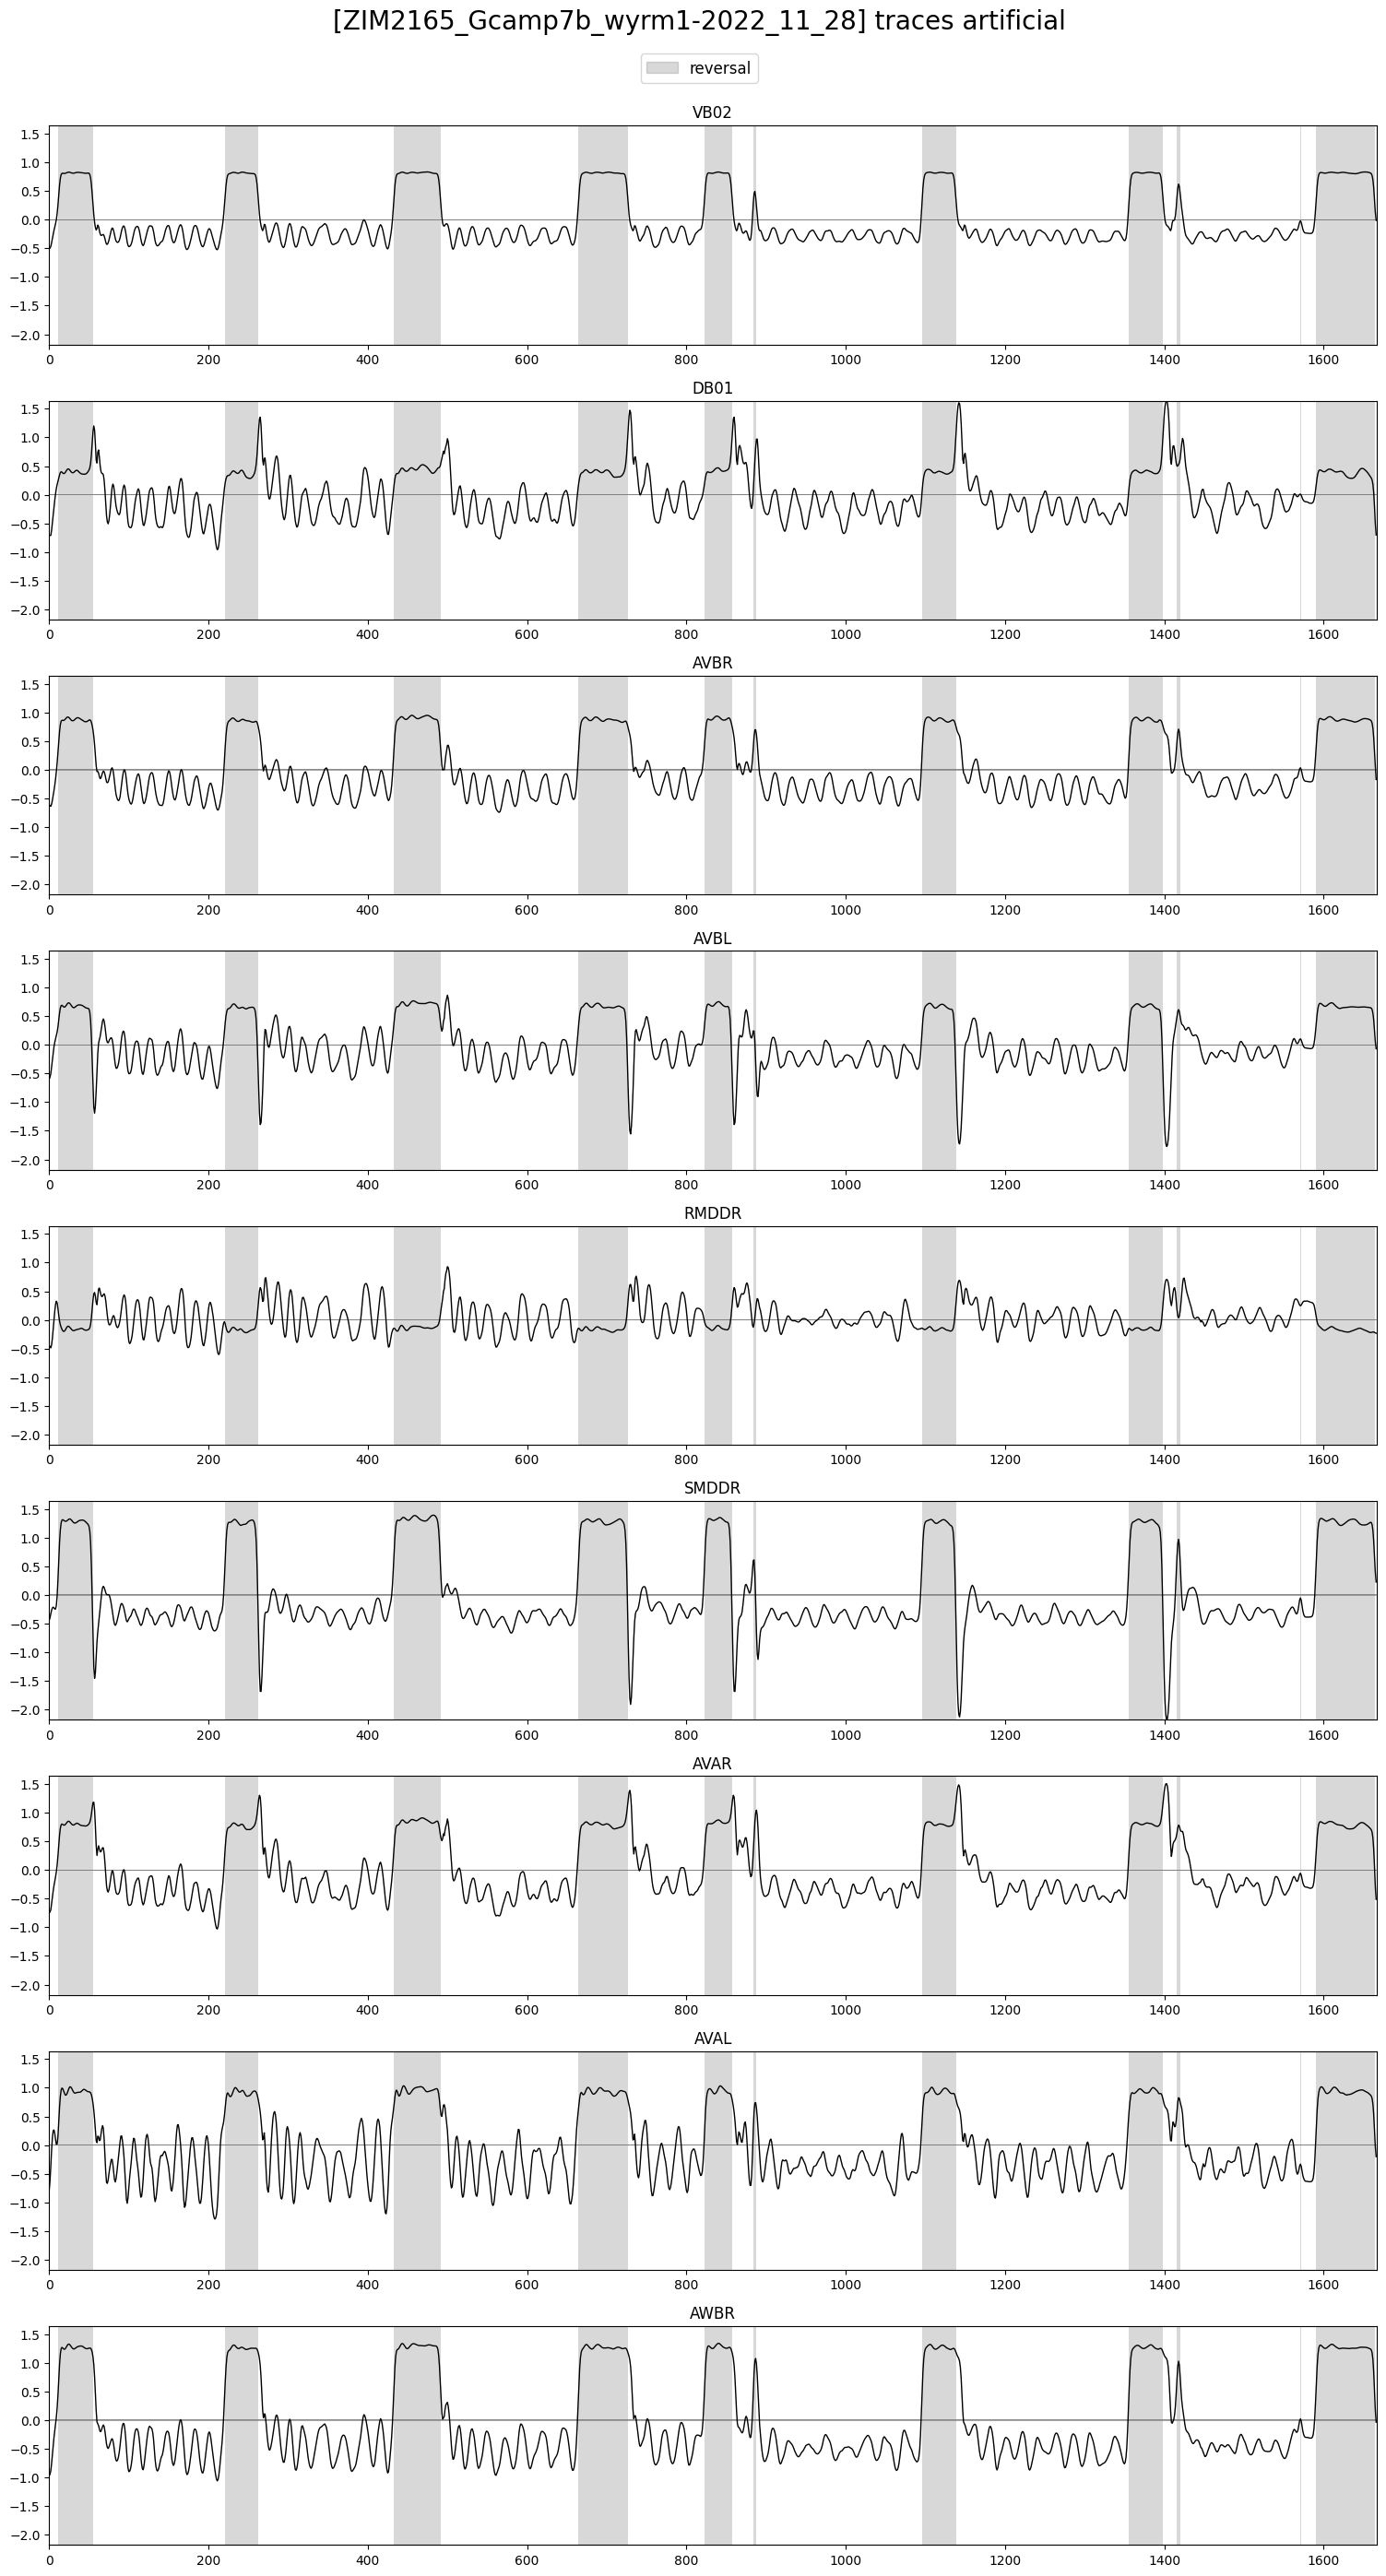

In [57]:
plot_utils.plot_traces(traces_art[plot_idx_art][selection_n],
					   discrete_states_art[plot_idx_art][['REV']],
					   label='reversal',
					   title=f'[{filenames_art[plot_idx_art]}] traces artificial', ylimits=None, plots_per_row=1)